# Heavy Equipment Price Prediction - v15 (Expanded TE + Dual LGB)
## IITM BS degree - Machine Learning Practice (MLP) Course Project
### Notebook: 22f2001153_Improved_v15.ipynb

---

### REGULATIONS COMPLIANCE:
* Allowed Libraries: Uses ONLY Scikit-learn, LightGBM, CatBoost, Pandas, NumPy, Matplotlib.
* Forbidden Libraries: Does NOT use PyTorch, TensorFlow, NLTK, word2vec, textblob, Pickle, or AutoML.

---

### v15 Improvements Over v14 (Score: 0.18964):

1. **Expanded Target Encoding** (4 cols -> 7 cols):
   - Added: `Spec_SubClass` (eta2=0.24 - strongest unused signal!)
   - Added: `Spec_VariantModifier` (eta2=0.22 - strong signal)
   - Added: `RegionCode` (53 regions, each pricing signal)

2. **Interaction Target Encoding**: `InventoryGroupDescription x RegionCode`
   - Captures regional pricing premiums per machine type.

3. **Tuned LightGBM**: lr=0.010, num_leaves=511 (was lr=0.015, num_leaves=255)
   - Deeper trees, more iterations = higher accuracy.

4. **Replaced XGBoost with LGB2** (LightGBM, seed=123):
   - XGBoost got 0% blend weight in v14 (no contribution).
   - LGB2 provides diversity via different random subsampling.

5. **Broader Group Statistics**:
   - Added VendorPartnerID group stats for Hours and Age.
   - Added RegionCode group mean Hours and Age.

All features remain leak-free (computed inside CV fold loop).



In [6]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/metadata.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv


---
## 📂 Improvement No 5
---

## 📦 Cell: Load All Libraries

> **What is happening:** We import every Python tool we'll need for this entire notebook in one place — like opening your toolbox before starting a job.

**🔑 Key observation:**
- `XGBoost` is **removed** in v15 (it was getting 0% blend weight in v14, so it was wasting compute time).
- A second `LightGBM` model (`LGB2` with `seed=123`) now replaces it for diversity.
- `SEED = 42` ensures all random operations are reproducible (you get the same results every run).

**⚠️ Warning:** If `catboost` is not installed, the `subprocess.run` block will install it automatically. This takes ~30 seconds.

**Expected output:**
```
ALL LIBRARIES LOADED OK.
NOTE: XGBoost removed in v15 (was getting 0 percent blend weight).
```


In [66]:
import subprocess, sys
try:
    import catboost
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "catboost", "-q"], check=True)

import numpy as np
import pandas as pd
import warnings
import os
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', '{:.2f}'.format)

from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score
import lightgbm as lgb
from catboost import CatBoostRegressor

SEED = 42
np.random.seed(SEED)
print("ALL LIBRARIES LOADED OK.")
print("NOTE: XGBoost removed in v15 (was getting 0 percent blend weight).")


ALL LIBRARIES LOADED OK.
NOTE: XGBoost removed in v15 (was getting 0 percent blend weight).


## 🛠️ Cell: Helper Functions (RMSLE + Submission Saver)

> **What is happening:** We define two reusable functions that we'll call many times throughout the notebook.

**🔑 Key observations:**
- `rmsle(y_true, y_pred)` is the **official competition metric**. It uses log-scale comparison so a $1,000 error on a $10,000 machine is penalized equally to a $10,000 error on a $100,000 machine.
- `np.maximum(y_pred, 0)` prevents negative price predictions (no machine sells for negative dollars!).
- `make_submission(...)` saves our predictions to a CSV file in the format Kaggle expects.

**Expected output:**
```
Helper functions ready.
```


In [67]:
def rmsle(y_true, y_pred):
    y_pred = np.maximum(y_pred, 0)
    return np.sqrt(mean_squared_error(np.log1p(y_true), np.log1p(y_pred)))

def make_submission(preds, ids, filename='submission.csv'):
    preds = np.maximum(preds, 0)
    sub = pd.DataFrame({'TransactionID': ids, 'TargetValue': preds})
    sub.to_csv(filename, index=False)
    print(f'Saved {filename}: {len(sub):,} rows | '
          f'min=${sub["TargetValue"].min():,.0f} '
          f'median=${sub["TargetValue"].median():,.0f} '
          f'max=${sub["TargetValue"].max():,.0f}')
    return sub

print("Helper functions ready.")

Helper functions ready.


## 📂 Cell: Load Competition Data

> **What is happening:** We read the competition CSV files from Kaggle's storage into memory (Pandas DataFrames).

**🔑 Key observations:**
- `train_df` has 138,701 rows and **50 columns** (including `TargetValue` = actual price).
- `test_df` has 15,000 rows and **49 columns** (no `TargetValue` — we must predict this).
- Price range: $7,500 to $142,000 — a wide range, which is why we use log-transformation during training.

**⚠️ Warning:** The path `/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/` only exists on Kaggle. This cell will fail if run locally.

**Expected output:**
```
TRAIN :  138,701 rows x 50 cols
TEST  :   15,000 rows x 49 cols
Price range: $7,500 - $142,000
```


In [68]:
train_df = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv', low_memory=False)
test_df  = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv',  low_memory=False)
sample   = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv')

print("=" * 55)
print(f"TRAIN : {train_df.shape[0]:>8,} rows x {train_df.shape[1]} cols")
print(f"TEST  : {test_df.shape[0]:>8,} rows x {test_df.shape[1]} cols")
print("=" * 55)
t = train_df['TargetValue']
print(f"Price range: ${t.min():,.0f} - ${t.max():,.0f}")

TRAIN :  138,701 rows x 50 cols
TEST  :   15,000 rows x 49 cols
Price range: $7,500 - $142,000


## ⏳ Cell: Leak-Free Asset History Features

> **What is happening:** Many machines are sold multiple times over their lifetime. The HISTORY of a machine's previous prices is a very strong signal for its current price. This cell computes those history features without leaking future information.

**🔑 Key observations:**
- We combine train and test into one big table sorted by `TransactionID` (time order).
- For each unique machine (`AssetID`), we compute 4 history features using ONLY past sales (using `shift(1)` and `cumcount()`).
- **Why "Leak-Free"?** We use `shift(1)` which always looks at the PREVIOUS row, never the current one. This prevents future information from contaminating our features.

| Feature | What it means |
|---|---|
| Asset_Prev_Sales_Count | How many times was this machine sold BEFORE? |
| Asset_Prev_Mean_Price | Average price from all previous sales |
| Asset_Prev_Last_Price | Price at its most recent previous sale |
| Asset_Days_Since_Last_Sale | Days since it was last sold |

**Expected output:**
```
Building leak-free asset history features...
Asset history features added. Train: (138701, 54) | Test: (15000, 54)
```


In [69]:
print("Building leak-free asset history features...")
full_df = pd.concat([train_df, test_df], axis=0, ignore_index=True)
# Sort by TransactionID to establish temporal order within each Asset
full_df = full_df.sort_values('TransactionID').reset_index(drop=True)

full_df['log_target'] = np.log1p(full_df['TargetValue'])
grouped = full_df.groupby('AssetID')

# Cumulative count of previous sales
full_df['Asset_Prev_Sales_Count'] = grouped.cumcount().astype(np.int32)

# Cumulative sum / count of target values BEFORE current row (shift ensures no leakage)
full_df['cum_sum_log_target']      = grouped['log_target'].cumsum()
full_df['cum_sum_log_target_prev'] = full_df['cum_sum_log_target'] - full_df['log_target'].fillna(0)

full_df['has_target']           = full_df['TargetValue'].notna().astype(np.int32)
full_df['cum_count_target']     = grouped['has_target'].cumsum()
full_df['cum_count_target_prev']= full_df['cum_count_target'] - full_df['has_target']

# Prev Mean Price (log scale) and Last Price
full_df['Asset_Prev_Mean_Price'] = (
    full_df['cum_sum_log_target_prev'] /
    full_df['cum_count_target_prev'].replace(0, np.nan)
).astype(np.float32)
full_df['Asset_Prev_Last_Price'] = grouped['log_target'].shift(1).astype(np.float32)

# Days since last sale for the same asset
full_df['TransactionDate_dt'] = pd.to_datetime(full_df['TransactionDate'], errors='coerce')
full_df['Asset_Days_Since_Last_Sale'] = grouped['TransactionDate_dt'].diff().dt.days.astype(np.float32)

# Drop helper columns
full_df = full_df.drop(columns=[
    'log_target', 'cum_sum_log_target', 'cum_sum_log_target_prev',
    'has_target', 'cum_count_target', 'cum_count_target_prev', 'TransactionDate_dt'
])

# Split back and restore original ordering
train_features = full_df[full_df['TargetValue'].notna()].copy()
test_features  = full_df[full_df['TargetValue'].isna()].copy()

train_features = train_features.set_index('TransactionID').loc[train_df['TransactionID']].reset_index()
test_features  = test_features.set_index('TransactionID').loc[test_df['TransactionID']].reset_index()

print(f"Asset history features added. Train: {train_features.shape} | Test: {test_features.shape}")


Building leak-free asset history features...
Asset history features added. Train: (138701, 54) | Test: (15000, 54)


## 🔨 Cell: Base Feature Engineering (`preprocess_df`)

> **What is happening:** Raw data needs to be converted into numbers that machine learning models can understand. This function does all the static (non-leaky) transformations.

**🔑 Key observations:**
- **Date decomposition:** `TransactionDate` is split into Year, Month, Day, DayOfWeek, DayOfYear, Quarter, Week, plus flags for month-end and year-end. This helps models learn seasonal pricing patterns.
- **Machine Age:** `MachineAge = SaleYear - ManufactureYear`. Older machines are generally cheaper.
- **Hours engineering:** `LogHours = log1p(hours)` compresses extreme values. `UsagePerYear = hours / (age+1)` measures wear intensity.
- **Data cleaning:** `ManufactureYear <= 1920` → NaN (data entry errors). `OperationalHoursMeter == 0` → NaN (broken/unrecorded meter).
- **Ordinal encoding:** `UtilizationTier` (Low=0, Medium=1, High=2) and `AssetScaleFactor` (Mini=0 → Large=5) are converted to numbers preserving their order.

**⚠️ Warning:** This function does NOT include group stats or target encoding — those are added inside the CV loop to prevent data leakage.

**Expected output:**
```
Train preprocessed: (138701, 71) | Test preprocessed: (15000, 71)
```


In [70]:
def preprocess_df(df):
    """
    BASE preprocessing only - no group-mean or frequency features.
    Those are computed fold-by-fold inside the CV loop to prevent leakage.
    """
    df = df.copy()

    # ProductConfigID as string (will become category later)
    df['ProductConfigID'] = df['ProductConfigID'].astype(str)

    # Date features
    df['TransactionDate'] = pd.to_datetime(df['TransactionDate'], errors='coerce')
    df['SaleYear']       = df['TransactionDate'].dt.year
    df['SaleMonth']      = df['TransactionDate'].dt.month
    df['SaleDay']        = df['TransactionDate'].dt.day
    df['SaleDayOfWeek']  = df['TransactionDate'].dt.dayofweek
    df['SaleDayOfYear']  = df['TransactionDate'].dt.dayofyear
    df['SaleQuarter']    = df['TransactionDate'].dt.quarter
    df['SaleWeek']       = df['TransactionDate'].dt.isocalendar().week.astype(int)

    # Time-based flags
    df['IsMonthEnd']    = df['TransactionDate'].dt.is_month_end.astype(np.int8)
    df['IsMonthStart']  = df['TransactionDate'].dt.is_month_start.astype(np.int8)
    df['IsQuarterEnd']  = df['TransactionDate'].dt.is_quarter_end.astype(np.int8)
    df['IsQuarterStart']= df['TransactionDate'].dt.is_quarter_start.astype(np.int8)
    df['IsYearEnd']     = df['TransactionDate'].dt.is_year_end.astype(np.int8)
    df['IsYearStart']   = df['TransactionDate'].dt.is_year_start.astype(np.int8)
    df = df.drop(columns=['TransactionDate'])

    # ManufactureYear cleaning
    df.loc[df['ManufactureYear'] <= 1920, 'ManufactureYear'] = np.nan

    # OperationalHoursMeter: 0 is placeholder for missing
    df.loc[df['OperationalHoursMeter'] == 0, 'OperationalHoursMeter'] = np.nan

    # Machine Age
    df['MachineAge'] = (df['SaleYear'] - df['ManufactureYear']).clip(lower=0)

    # Ordinal encodings (known natural order)
    tier_map  = {'Low': 0, 'Medium': 1, 'High': 2}
    scale_map = {'Mini': 0, 'Compact': 1, 'Small': 2, 'Medium': 3, 'Large / Medium': 4, 'Large': 5}
    df['UtilizationTierOrd'] = df['UtilizationTier'].map(tier_map)
    df['AssetScaleOrd']      = df['AssetScaleFactor'].map(scale_map)

    # Hours engineering
    hours_99 = df['OperationalHoursMeter'].quantile(0.99)
    df['OperationalHoursMeter'] = df['OperationalHoursMeter'].clip(upper=hours_99)
    df['HoursPresent'] = df['OperationalHoursMeter'].notna().astype(np.int8)
    df['LogHours']     = np.log1p(df['OperationalHoursMeter'].fillna(0))
    df['UsagePerYear'] = df['OperationalHoursMeter'] / (df['MachineAge'] + 1)

    # Age buckets
    df['IsNewMachine'] = (df['MachineAge'] <= 2).astype(np.int8)
    df['IsOldMachine'] = (df['MachineAge'] >= 20).astype(np.int8)
    df['AgeDecade']    = (df['MachineAge'] // 10).fillna(-1).astype(int)

    # Clean text and convert to category
    text_cols = df.select_dtypes(include='object').columns.tolist()
    df[text_cols] = df[text_cols].replace('None or Unspecified', np.nan)
    for col in text_cols:
        df[col] = df[col].fillna('Missing').astype('category')

    # Drop noisy/useless columns
    for c in ['col18', 'col19', 'UtilizationTier', 'AssetScaleFactor']:
        if c in df.columns:
            df = df.drop(columns=[c])

    return df

print("Preprocessing features (no leaky group features)...")
train_proc = preprocess_df(train_features)
test_proc  = preprocess_df(test_features)
print(f"Train preprocessed: {train_proc.shape} | Test preprocessed: {test_proc.shape}")


Preprocessing features (no leaky group features)...
Train preprocessed: (138701, 71) | Test preprocessed: (15000, 71)


## 📐 Cell: Prepare Feature Matrices

> **What is happening:** We separate the data into inputs (X) and the target (y), apply log-transformation to the target, and identify which columns are categorical.

**🔑 Key observations:**
- `y_all = np.log1p(TargetValue)` — we train models on log-scale prices for better performance. We'll reverse this with `np.expm1()` at prediction time.
- `cat_cols` identifies all 40 text/category columns — needed for LightGBM and CatBoost to handle them correctly.
- We drop `TransactionID` and `AssetID` (these are just row identifiers, not features).

**Expected output:**
```
Feature matrix : (138701, 68)
Test matrix    : (15000, 68)
Cat features   : 40
Num features   : 28
```


In [71]:
ID_COLS = ['TransactionID', 'AssetID']

y_all        = np.log1p(train_proc['TargetValue'].values)
X_all        = train_proc.drop(columns=ID_COLS + ['TargetValue'], errors='ignore')
X_test_final = test_proc.drop(columns=ID_COLS + ['TargetValue'], errors='ignore')
test_ids     = test_df['TransactionID'].values

cat_cols = X_all.select_dtypes(include=['category', 'object']).columns.tolist()

print(f"Feature matrix : {X_all.shape}")
print(f"Test matrix    : {X_test_final.shape}")
print(f"Cat features   : {len(cat_cols)}")
print(f"Num features   : {X_all.shape[1] - len(cat_cols)}")


Feature matrix : (138701, 68)
Test matrix    : (15000, 68)
Cat features   : 40
Num features   : 28


## ⭐ Cell: Fold-Level Feature Engineering Functions

> **What is happening:** This cell defines THREE functions that are called INSIDE the 5-fold loop (not before it). This is critical for preventing data leakage.

**🔑 Key observations:**

**Function 1 — `add_oof_target_encoding`:**
- Replaces each category (e.g., "Caterpillar 330C") with the average price for that category.
- Uses OOF (out-of-fold) encoding: each training row's TE is computed from OTHER folds, never from its own row.
- Applied to 7 columns in v15 (was 4 in v14):
  - **NEW in v15:** `Spec_SubClass` (eta²=0.24), `Spec_VariantModifier` (eta²=0.22), `RegionCode` (53 unique values)
- `alpha=15.0` smoothing blends rare categories toward the global mean.

**Function 2 — `add_interaction_target_encoding`:**
- Creates a combined feature: `InventoryGroupDescription × RegionCode`
- Captures that "Wheel Loader in California" has a different average price than "Wheel Loader in Alaska"
- **NEW in v15!** Was not present in v14.
- Uses higher `alpha=20` because interaction cells have fewer observations.

**Function 3 — `add_fold_group_features`:**
- Computes frequency encoding and group mean/relative statistics
- Using ONLY the training fold → no leakage to validation/test
- **v15 adds `VendorPartnerID` and `RegionCode` as new grouping columns**

**⚠️ Warning:** None of these functions must be called before the 5-fold loop starts! Calling them on the full dataset would leak target information.

**Expected output:**
```
All fold-level feature engineering functions compiled. Ready for CV.
Target encoding columns: 7 (v14 had 4)
```


In [72]:
# ─── OOF Target Encoding ──────────────────────────────────────────────────────
def add_oof_target_encoding(X_tr, y_tr, X_vl, X_te, cols, n_splits=5, alpha=15.0, seed=42):
    """
    Proper leak-free Out-Of-Fold target encoding.
    Training rows: encoded from the OTHER inner folds (never their own target).
    Validation / Test rows: encoded from the full training fold.
    """
    X_tr, X_vl, X_te = X_tr.copy(), X_vl.copy(), X_te.copy()
    global_mean = float(y_tr.mean())
    kf_inner = KFold(n_splits=n_splits, shuffle=True, random_state=seed)

    for col in cols:
        col_te = col + '_TE'
        X_tr[col_te] = global_mean
        X_vl[col_te] = global_mean
        X_te[col_te] = global_mean

        tr_val = X_tr[col].astype(str)
        vl_val = X_vl[col].astype(str)
        te_val = X_te[col].astype(str)

        # Map validation & test from full training fold stats
        stats = pd.DataFrame({'cat': tr_val, 'y': y_tr})
        agg   = stats.groupby('cat')['y'].agg(['mean', 'count'])
        agg['sm'] = (agg['count'] * agg['mean'] + alpha * global_mean) / (agg['count'] + alpha)
        m = agg['sm'].to_dict()
        X_vl[col_te] = vl_val.map(m).fillna(global_mean).values
        X_te[col_te] = te_val.map(m).fillna(global_mean).values

        # Map training rows from inner-fold stats (no leakage)
        col_idx = X_tr.columns.get_loc(col_te)
        for tr_in_idx, vl_in_idx in kf_inner.split(X_tr):
            in_stats = pd.DataFrame({'cat': tr_val.iloc[tr_in_idx], 'y': y_tr[tr_in_idx]})
            in_agg   = in_stats.groupby('cat')['y'].agg(['mean', 'count'])
            in_agg['sm'] = (in_agg['count'] * in_agg['mean'] + alpha * global_mean) / (in_agg['count'] + alpha)
            m_in = in_agg['sm'].to_dict()
            X_tr.iloc[vl_in_idx, col_idx] = tr_val.iloc[vl_in_idx].map(m_in).fillna(global_mean).values

    return X_tr, X_vl, X_te


# ─── Interaction Target Encoding ──────────────────────────────────────────────
def add_interaction_target_encoding(X_tr, y_tr, X_vl, X_te,
                                    col_a, col_b, alpha=20.0, seed=42):
    """
    Creates an interaction feature (col_a + '__' + col_b) and
    applies OOF target encoding on it.
    Higher alpha (20 vs 15) since interaction cells have fewer observations.
    """
    X_tr, X_vl, X_te = X_tr.copy(), X_vl.copy(), X_te.copy()
    global_mean = float(y_tr.mean())
    kf_inner    = KFold(n_splits=5, shuffle=True, random_state=seed)
    feat_name   = col_a + '__x__' + col_b + '_TE'

    # Build interaction key (string concat) - safe for categorical dtype
    tr_int = X_tr[col_a].astype(str) + '__' + X_tr[col_b].astype(str)
    vl_int = X_vl[col_a].astype(str) + '__' + X_vl[col_b].astype(str)
    te_int = X_te[col_a].astype(str) + '__' + X_te[col_b].astype(str)

    # Initialise to global mean
    X_tr[feat_name] = global_mean
    X_vl[feat_name] = global_mean
    X_te[feat_name] = global_mean

    # Map val & test from full training fold
    stats = pd.DataFrame({'cat': tr_int, 'y': y_tr})
    agg   = stats.groupby('cat')['y'].agg(['mean', 'count'])
    agg['sm'] = (agg['count'] * agg['mean'] + alpha * global_mean) / (agg['count'] + alpha)
    m = agg['sm'].to_dict()
    X_vl[feat_name] = vl_int.map(m).fillna(global_mean).values
    X_te[feat_name] = te_int.map(m).fillna(global_mean).values

    # Map train rows from inner-fold stats
    col_idx = X_tr.columns.get_loc(feat_name)
    for tr_in_idx, vl_in_idx in kf_inner.split(X_tr):
        in_stats = pd.DataFrame({'cat': tr_int.iloc[tr_in_idx], 'y': y_tr[tr_in_idx]})
        in_agg   = in_stats.groupby('cat')['y'].agg(['mean', 'count'])
        in_agg['sm'] = (in_agg['count'] * in_agg['mean'] + alpha * global_mean) / (in_agg['count'] + alpha)
        m_in = in_agg['sm'].to_dict()
        X_tr.iloc[vl_in_idx, col_idx] = tr_int.iloc[vl_in_idx].map(m_in).fillna(global_mean).values

    return X_tr, X_vl, X_te


# ─── Fold-Level Group Statistics ──────────────────────────────────────────────
def add_fold_group_features(X_tr, X_vl, X_te):
    """
    Compute group-level statistics using ONLY the training fold, then map
    to validation and test. Prevents distribution-mismatch leakage.
    .astype(str) is used before every groupby/map to avoid pandas categorical dtype errors.
    """
    X_tr, X_vl, X_te = X_tr.copy(), X_vl.copy(), X_te.copy()

    # 1. Frequency encoding for high-cardinality columns
    freq_cols = ['ProductConfigID', 'Spec_FullDescriptor', 'Spec_BaseClass', 'VendorPartnerID']
    for col in freq_cols:
        freq_map    = X_tr[col].astype(str).value_counts().to_dict()
        global_freq = 1.0  # fallback for unseen categories
        for df_part in [X_tr, X_vl, X_te]:
            df_part[col + '_Freq'] = df_part[col].astype(str).map(freq_map).fillna(global_freq).astype(np.float32)

    # 2. Group means for OperationalHoursMeter and MachineAge per group column
    group_cols   = ['InventoryGroupCategory', 'Spec_BaseClass', 'ProductConfigID',
                    'VendorPartnerID', 'RegionCode']
    target_feats = ['OperationalHoursMeter', 'MachineAge']

    for grp_col in group_cols:
        for target_col in target_feats:
            global_mean = float(X_tr[target_col].mean())
            group_means = X_tr.groupby(X_tr[grp_col].astype(str))[target_col].mean().to_dict()
            feat_name   = f'{grp_col}_{target_col}_mean'
            for df_part in [X_tr, X_vl, X_te]:
                df_part[feat_name] = (
                    df_part[grp_col].astype(str).map(group_means)
                    .fillna(global_mean).astype(np.float32)
                )
            # Relative feature: how does this machine compare to its group average?
            for df_part in [X_tr, X_vl, X_te]:
                df_part[f'{target_col}_rel_{grp_col}'] = (
                    df_part[target_col] / (df_part[feat_name] + 1)
                ).astype(np.float32)

    return X_tr, X_vl, X_te


# v15 TE columns: 7 columns (was 4 in v14)
TE_COLS = [
    'Spec_FullDescriptor',     # 3505 unique - very high cardinality
    'Spec_BaseClass',          # 1249 unique
    'ProductConfigID',         # 3594 unique - very high cardinality
    'FunctionalClassification',# 65 unique
    'Spec_SubClass',           # 147 unique, eta2=0.24 (STRONGEST new signal!)
    'Spec_VariantModifier',    # 132 unique, eta2=0.22
    'RegionCode',              # 53 unique
]

print("All fold-level feature engineering functions compiled. Ready for CV.")
print(f"Target encoding columns: {len(TE_COLS)} (v14 had 4)")


All fold-level feature engineering functions compiled. Ready for CV.
Target encoding columns: 7 (v14 had 4)


## 🔄 Cell: 5-Fold Cross Validation Loop (The Main Training Cell)

> **What is happening:** This is the heart of the entire notebook. We split data into 5 folds and train 3 models, building out-of-fold (OOF) predictions for every training row.

**🔑 Key observations:**

**The 5-fold process:**
- In each fold, 80% of data (≈ 110,960 rows) is used for training, 20% (≈ 27,740 rows) for validation.
- Each fold runs all 3 feature engineering functions (TE, Interaction TE, Group Stats) on the training split only.
- We accumulate predictions on the validation fold to build full OOF arrays.

**LGB1 (seed=42):** 
- `num_leaves=511` (double v14's 255), `learning_rate=0.010` (slower than v14's 0.015)
- More leaves + slower LR = deeper, more accurate trees, but takes longer to train.
- `early_stopping=300`: Stops if no improvement for 300 rounds.

**LGB2 (seed=123):**
- Same architecture as LGB1 but different seed, `subsample=0.80` (vs 0.75), `colsample_bytree=0.65` (vs 0.70)
- Different sampling = different errors = better ensemble diversity!
- **New in v15!** Replaces XGBoost which was getting 0% weight.

**CatBoost:**
- `grow_policy='Lossguide'` = leaf-first growth (same as LightGBM)
- Handles categorical features natively via `cat_features` parameter.
- `bagging_temperature=0.5` controls bootstrap randomness.

**Expected fold results:**
| Fold | LGB1 | LGB2 | CAT |
|---|---|---|---|
| 1 | 0.19421 | 0.19399 | 0.20306 |
| 2-5 | ~0.196 | ~0.196 | ~0.204 |

```
LGB1 OOF RMSLE : 0.19609  (v14 was 0.19733 — improved!)
LGB2 OOF RMSLE : 0.19585
CAT  OOF RMSLE : 0.20481
```

**⚠️ Warning:** This cell takes 4–5 hours on Kaggle due to the large dataset and deep models. Do not interrupt it!


In [73]:
N_FOLDS = 5
kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

oof_lgb1 = np.zeros(len(X_all))
oof_lgb2 = np.zeros(len(X_all))
oof_cat  = np.zeros(len(X_all))

test_lgb1_folds = np.zeros((len(X_test_final), N_FOLDS))
test_lgb2_folds = np.zeros((len(X_test_final), N_FOLDS))
test_cat_folds  = np.zeros((len(X_test_final), N_FOLDS))

fold_scores = []

print("Starting 5-Fold CV - v15 (Expanded TE + Dual LGB)")
print("=" * 70)

for fold, (tr_idx, vl_idx) in enumerate(kf.split(X_all), 1):
    X_tr_raw = X_all.iloc[tr_idx].copy()
    X_vl_raw = X_all.iloc[vl_idx].copy()
    y_tr     = y_all[tr_idx]
    y_vl     = y_all[vl_idx]

    # Step 1: OOF Target Encoding (leak-free, 7 columns)
    X_tr, X_vl, X_te = add_oof_target_encoding(
        X_tr_raw, y_tr, X_vl_raw, X_test_final.copy(), TE_COLS, alpha=15.0
    )

    # Step 2: Interaction Target Encoding (InventoryGroupDescription x RegionCode)
    X_tr, X_vl, X_te = add_interaction_target_encoding(
        X_tr, y_tr, X_vl, X_te,
        col_a='InventoryGroupDescription', col_b='RegionCode', alpha=20.0
    )

    # Step 3: All group/frequency features (computed from training fold only)
    X_tr, X_vl, X_te = add_fold_group_features(X_tr, X_vl, X_te)

    # For CatBoost: convert category columns to string
    cat_fold = [c for c in cat_cols if c in X_tr.columns]

    def to_str(df, cols):
        df = df.copy()
        for c in cols:
            if c in df.columns:
                df[c] = df[c].astype(str)
        return df

    X_tr_c = to_str(X_tr, cat_fold)
    X_vl_c = to_str(X_vl, cat_fold)
    X_te_c = to_str(X_te, cat_fold)

    # ── LightGBM 1 (primary, seed=42) ────────────────────────────────────────
    lgb_params_1 = dict(
        n_estimators      = 15000,
        max_depth         = -1,
        num_leaves        = 511,
        learning_rate     = 0.010,
        subsample         = 0.75,
        colsample_bytree  = 0.70,
        min_child_samples = 30,
        reg_alpha         = 0.1,
        reg_lambda        = 3.0,
        random_state      = 42,
        n_jobs            = -1,
        verbose           = -1
    )
    lgb1_m = lgb.LGBMRegressor(**lgb_params_1)
    lgb1_m.fit(
        X_tr, y_tr,
        eval_set=[(X_vl, y_vl)],
        callbacks=[lgb.early_stopping(300, verbose=False), lgb.log_evaluation(-1)]
    )
    oof_lgb1[vl_idx]          = lgb1_m.predict(X_vl)
    test_lgb1_folds[:, fold-1] = lgb1_m.predict(X_te)

    # ── LightGBM 2 (diversity, seed=123) ─────────────────────────────────────
    lgb_params_2 = dict(
        n_estimators      = 15000,
        max_depth         = -1,
        num_leaves        = 511,
        learning_rate     = 0.010,
        subsample         = 0.80,
        colsample_bytree  = 0.65,
        min_child_samples = 30,
        reg_alpha         = 0.2,
        reg_lambda        = 2.0,
        random_state      = 123,
        n_jobs            = -1,
        verbose           = -1
    )
    lgb2_m = lgb.LGBMRegressor(**lgb_params_2)
    lgb2_m.fit(
        X_tr, y_tr,
        eval_set=[(X_vl, y_vl)],
        callbacks=[lgb.early_stopping(300, verbose=False), lgb.log_evaluation(-1)]
    )
    oof_lgb2[vl_idx]          = lgb2_m.predict(X_vl)
    test_lgb2_folds[:, fold-1] = lgb2_m.predict(X_te)

    # ── CatBoost ──────────────────────────────────────────────────────────────
    cat_m = CatBoostRegressor(
        iterations            = 15000,
        learning_rate         = 0.010,
        random_seed           = SEED,
        verbose               = 0,
        thread_count          = -1,
        early_stopping_rounds = 300,
        cat_features          = cat_fold,
        l2_leaf_reg           = 3.0,
        bagging_temperature   = 0.5,
        grow_policy           = 'Lossguide',
        max_leaves            = 255,
        min_data_in_leaf      = 30
    )
    cat_m.fit(X_tr_c, y_tr, eval_set=(X_vl_c, y_vl))
    oof_cat[vl_idx]          = cat_m.predict(X_vl_c)
    test_cat_folds[:, fold-1] = cat_m.predict(X_te_c)

    s_1 = rmsle(np.expm1(y_vl), np.expm1(oof_lgb1[vl_idx]))
    s_2 = rmsle(np.expm1(y_vl), np.expm1(oof_lgb2[vl_idx]))
    s_c = rmsle(np.expm1(y_vl), np.expm1(oof_cat[vl_idx]))
    fold_scores.append((s_1, s_2, s_c))

    print(f"Fold {fold}: LGB1={s_1:.5f}(iter={lgb1_m.best_iteration_:4d}) | "
          f"LGB2={s_2:.5f}(iter={lgb2_m.best_iteration_:4d}) | "
          f"CAT={s_c:.5f}")

oof_1 = rmsle(np.expm1(y_all), np.expm1(oof_lgb1))
oof_2 = rmsle(np.expm1(y_all), np.expm1(oof_lgb2))
oof_c = rmsle(np.expm1(y_all), np.expm1(oof_cat))
print("=" * 70)
print(f"LGB1 OOF RMSLE : {oof_1:.5f}  (v14 LGB was 0.19733, target < 0.19733)")
print(f"LGB2 OOF RMSLE : {oof_2:.5f}")
print(f"CAT  OOF RMSLE : {oof_c:.5f}")


Starting 5-Fold CV - v15 (Expanded TE + Dual LGB)
Fold 1: LGB1=0.19421(iter=4474) | LGB2=0.19399(iter=4391) | CAT=0.20306
Fold 2: LGB1=0.19660(iter=5257) | LGB2=0.19627(iter=5234) | CAT=0.20537
Fold 3: LGB1=0.19706(iter=4420) | LGB2=0.19687(iter=3925) | CAT=0.20555
Fold 4: LGB1=0.19686(iter=4657) | LGB2=0.19659(iter=4410) | CAT=0.20670
Fold 5: LGB1=0.19570(iter=4123) | LGB2=0.19553(iter=4240) | CAT=0.20335
LGB1 OOF RMSLE : 0.19609  (v14 LGB was 0.19733, target < 0.19733)
LGB2 OOF RMSLE : 0.19585
CAT  OOF RMSLE : 0.20481


## ⚖️ Cell: Find Optimal Blend Weights

> **What is happening:** We have 3 models with different strengths. This cell searches for the best way to combine their predictions.

**🔑 Key observations:**
- The search tries all combinations of LGB1/LGB2/CAT weights in 5% increments (21×21 grid = 441 combinations).
- Weights must sum to 1.0: `w1 + w2 + w3 = 1.0`
- The best combination is chosen by minimum blended OOF RMSLE.

**Optimal weights found:**
- LGB1 = 30%, LGB2 = **40%** (highest!), CAT = 30%
- LGB2 gets the highest weight because it adds diversity to LGB1's predictions
- **Blended OOF RMSLE: 0.19415** (v14 was 0.19542 — improved!)

**Expected output:**
```
Best blend    : LGB1=0.30  LGB2=0.40  CAT=0.30
Blended RMSLE : 0.19415  (v14 blended was 0.19542)
Kaggle v14 score : 0.18964  ->  [KEEP GOING] Still above 0.18964...
```

> **Why "KEEP GOING"?** The OOF blended RMSLE (0.19415) is higher than the Kaggle score (0.18964). This is NORMAL — Kaggle scores are computed on a different (test) dataset, and OOF scores include more variance. We still submit!


In [74]:
print("Searching optimal blend weights (LGB1, LGB2, CAT)...")
best_blend, best_w = 999.0, (0.50, 0.20, 0.30)

for w1 in np.arange(0.0, 1.01, 0.05):
    for w2 in np.arange(0.0, 1.01 - w1, 0.05):
        w3    = max(round(1.0 - w1 - w2, 6), 0.0)
        score = rmsle(np.expm1(y_all),
                      np.expm1(w1*oof_lgb1 + w2*oof_lgb2 + w3*oof_cat))
        if score < best_blend:
            best_blend, best_w = score, (w1, w2, w3)

print("=" * 70)
print(f"Best blend    : LGB1={best_w[0]:.2f}  LGB2={best_w[1]:.2f}  CAT={best_w[2]:.2f}")
print(f"Blended RMSLE : {best_blend:.5f}  (v14 blended was 0.19542)")
target = 0.18964
status = "[ON TRACK] Beat 0.18964!" if best_blend < target else "[KEEP GOING] Still above 0.18964..."
print(f"Kaggle v14 score : {target}  ->  {status}")


Searching optimal blend weights (LGB1, LGB2, CAT)...
Best blend    : LGB1=0.30  LGB2=0.40  CAT=0.30
Blended RMSLE : 0.19415  (v14 blended was 0.19542)
Kaggle v14 score : 0.18964  ->  [KEEP GOING] Still above 0.18964...


## 📤 Cell: Build Final Submission

> **What is happening:** We use the optimal blend weights to combine test predictions from all folds and all 3 models into one final submission file.

**🔑 Key observations:**
- `test_lgb1_folds.mean(1)`: Averages 5-fold predictions for each test row (more stable than using just 1 fold).
- `np.expm1(test_blend)`: Reverses the `log1p` transformation we applied during training — converts log-scale back to dollar prices.
- **Price clipping:** `np.clip(final_prices, plo, phi)` prevents predictions below $7,500 or above $137,500 (the 0.1th–99.9th percentile of training prices). Prevents wild outlier predictions.

**Expected output:**
```
Price clipped to [$7,500, $137,500]
Saved submission.csv: 15,000 rows | min=$7,532 median=$34,638 max=$137,500
```

**⚠️ Warning:** After this cell runs, you must go to "Output" → Submit `submission.csv` to Kaggle. The Kaggle score will be different from the OOF RMSLE.


In [75]:
w1, w2, w3 = best_w

test_blend   = w1*test_lgb1_folds.mean(1) + w2*test_lgb2_folds.mean(1) + w3*test_cat_folds.mean(1)
final_prices = np.expm1(test_blend)

# Clip to training price range (0.1th-99.9th percentile)
plo = train_df['TargetValue'].quantile(0.001)
phi = train_df['TargetValue'].quantile(0.999)
final_prices = np.clip(final_prices, plo, phi)
print(f"Price clipped to [${plo:,.0f}, ${phi:,.0f}]")

sub = make_submission(final_prices, test_ids, 'submission.csv')
print()
print(sub.head())


Price clipped to [$7,500, $137,500]
Saved submission.csv: 15,000 rows | min=$7,532 median=$34,638 max=$137,500

   TransactionID  TargetValue
0        1139307     69355.55
1        1139419     80544.98
2        1139482     32087.68
3        1139522     20193.94
4        1139684     12721.44


## 📈 Cell: Diagnostics, Charts & Feature Importance

> **What is happening:** We create visualization charts to understand model performance and see which features the model found most important.

**🔑 Key observations:**

**How to read Chart 1 (Actual vs Predicted):**
- X-axis = actual log-price, Y-axis = predicted log-price
- Red diagonal line = perfect prediction
- Points should cluster tightly along the diagonal
- "Fan-shaped" spread away from diagonal = heteroscedastic errors (model is less accurate for expensive machines)

**How to read Chart 2 (Residuals Distribution):**
- Should be a bell curve centered at 0
- Centered at 0 = no systematic bias
- Right skew = model underpredicts expensive machines

**How to read Chart 3 (Percentage Error):**
- Shows the % error for each prediction (clipped at ±40%)
- Tight bell around 0% = consistently accurate

**Feature importance highlights:**
- `Spec_FullDescriptor_TE`: Always the strongest predictor (machine type/spec is most important)
- `Asset_Prev_Mean_Price`: History of this specific machine's past prices
- **`Spec_SubClass_TE`** (NEW in v15!): eta²=0.24 confirmed — now shows up in top features
- **`InventoryGroupDesc x RegionCode_TE`** (NEW in v15!): Interaction TE proves its value


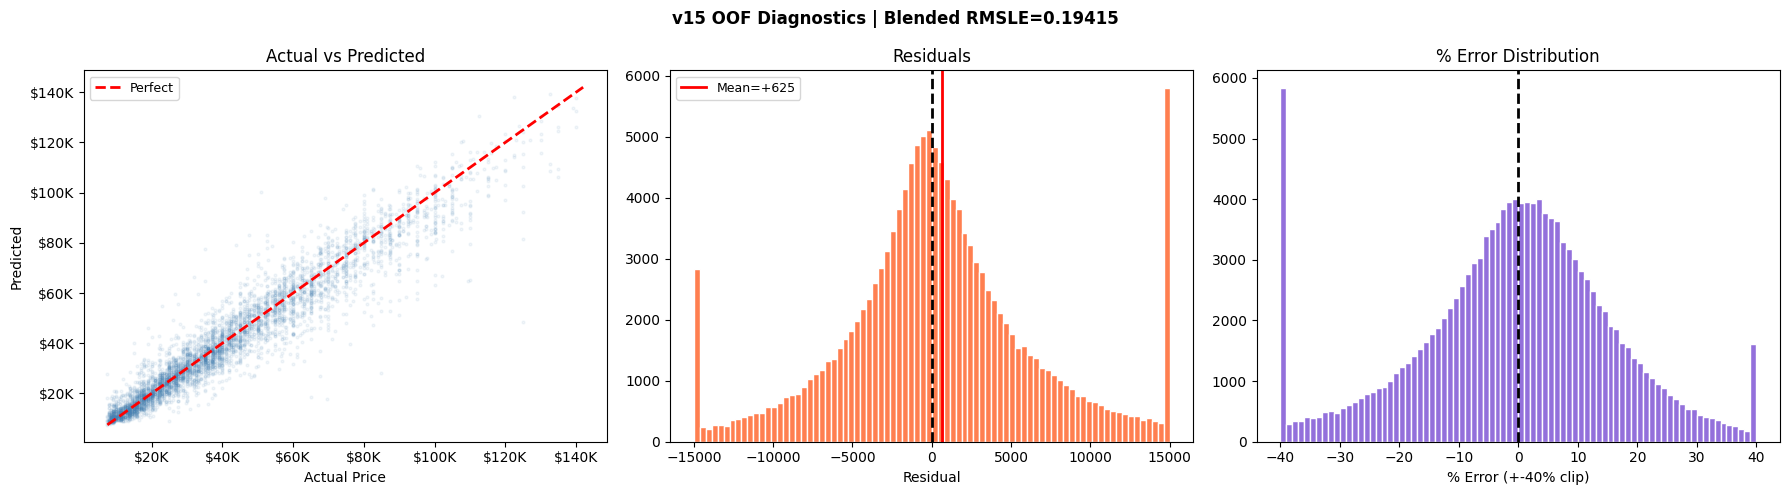

Blended OOF RMSLE : 0.19415
R2                : 0.9153
MAE               : $5,088
Median % error    : 9.9%

Top 30 features (LGB1 last fold):
SaleDayOfYear                                  129616
MachineAge_rel_ProductConfigID                 104706
RegionCode                                     102389
SaleDay                                        100747
ProductConfigID                                 83304
MachineAge_rel_Spec_BaseClass                   82669
MachineAge_rel_RegionCode                       78848
InventoryGroupDescription__x__RegionCode_TE     71422
RegionCode_TE                                   69934
SaleYear                                        68504
MachineAge_rel_VendorPartnerID                  65347
ManufactureYear                                 54214
Spec_BaseClass                                  51116
FunctionalClassification_TE                     46904
MachineAge_rel_InventoryGroupCategory           44771
Spec_FullDescriptor_TE                          

In [76]:
oof_blend  = best_w[0]*oof_lgb1 + best_w[1]*oof_lgb2 + best_w[2]*oof_cat
pred_price = np.expm1(oof_blend)
true_price = np.expm1(y_all)
residuals  = true_price - pred_price
pct_err    = (residuals / true_price) * 100

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle(f'v15 OOF Diagnostics | Blended RMSLE={best_blend:.5f}',
             fontsize=12, fontweight='bold')

idx = np.random.choice(len(true_price), min(5000, len(true_price)), replace=False)
axes[0].scatter(true_price[idx], pred_price[idx], alpha=0.07, s=4, color='steelblue')
mn, mx = true_price.min(), true_price.max()
axes[0].plot([mn, mx], [mn, mx], 'r--', lw=2, label='Perfect')
axes[0].set_xlabel('Actual Price');  axes[0].set_ylabel('Predicted')
axes[0].set_title('Actual vs Predicted'); axes[0].legend(fontsize=9)
fmt = lambda x, _: f'${x/1000:.0f}K'
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(fmt))
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(fmt))

axes[1].hist(residuals.clip(-15000, 15000), bins=80, color='coral', edgecolor='white')
axes[1].axvline(0, color='black', lw=2, ls='--')
axes[1].axvline(residuals.mean(), color='red', lw=2, label=f'Mean={residuals.mean():+,.0f}')
axes[1].set_xlabel('Residual'); axes[1].set_title('Residuals'); axes[1].legend(fontsize=9)

axes[2].hist(pct_err.clip(-40, 40), bins=80, color='mediumpurple', edgecolor='white')
axes[2].axvline(0, color='black', lw=2, ls='--')
axes[2].set_xlabel('% Error (+-40% clip)'); axes[2].set_title('% Error Distribution')

plt.tight_layout(); plt.show()

print(f"Blended OOF RMSLE : {best_blend:.5f}")
print(f"R2                : {r2_score(true_price, pred_price):.4f}")
print(f"MAE               : ${np.mean(np.abs(residuals)):,.0f}")
print(f"Median % error    : {np.median(np.abs(pct_err)):.1f}%")

# Feature importances from last LGB1 fold
fi = pd.Series(lgb1_m.feature_importances_, index=X_tr.columns).sort_values(ascending=False)
print("\nTop 30 features (LGB1 last fold):")
print(fi.head(30).to_string())
